In [5]:
from google.colab import drive
drive.mount("/content/drive")

import torch
import matplotlib.pyplot as plt

SAVE_DIR = "/content/drive/MyDrive/abliteration"
data = torch.load(f"{SAVE_DIR}/activations_train.pt")

harmful_acts  = data["harmful_acts"]
harmless_acts = data["harmless_acts"]
print(harmful_acts.shape, harmless_acts.shape)

Mounted at /content/drive
torch.Size([128, 28, 2048]) torch.Size([128, 28, 2048])


In [6]:
mean_harmful  = harmful_acts.mean(dim=0)
mean_harmless = harmless_acts.mean(dim=0)
diff = mean_harmful - mean_harmless   # candidate refusal direction for every layer

print(mean_harmful.shape, diff.shape)

torch.Size([28, 2048]) torch.Size([28, 2048])


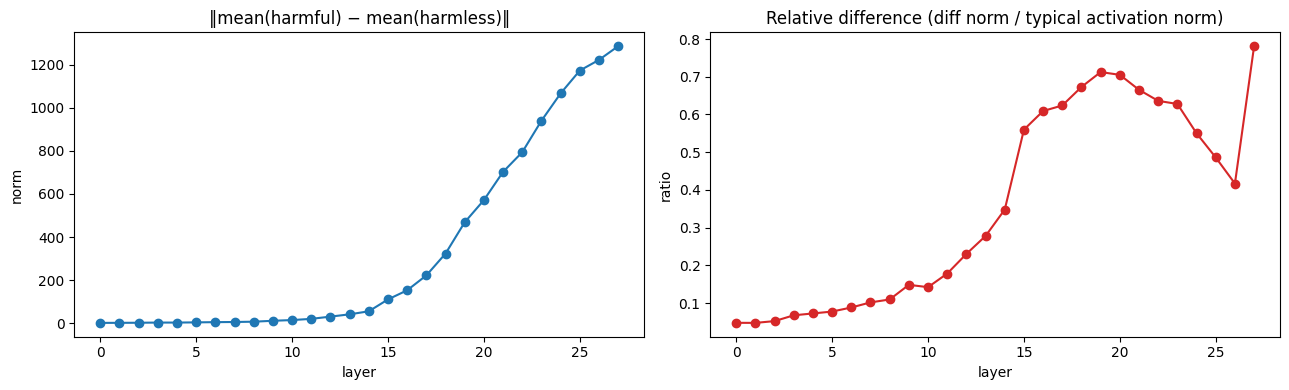

In [7]:
diff_norm = diff.norm(dim=-1)                          # size of the difference, per layer
act_norm  = harmless_acts.norm(dim=-1).mean(dim=0)     # typical notebook size, per layer

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(diff_norm, marker="o")
axes[0].set_title("‖mean(harmful) − mean(harmless)‖")
axes[0].set_xlabel("layer"); axes[0].set_ylabel("norm")

axes[1].plot(diff_norm / act_norm, marker="o", color="tab:red")
axes[1].set_title("Relative difference (diff norm / typical activation norm)")
axes[1].set_xlabel("layer"); axes[1].set_ylabel("ratio")
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/relative_difference.png", dpi=150)
plt.show()

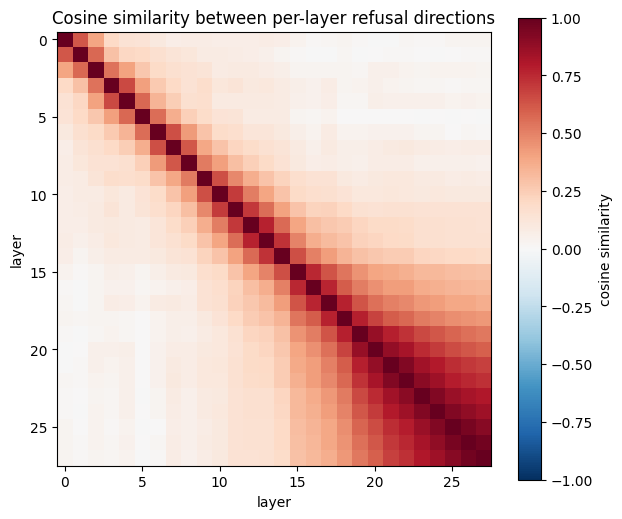

In [8]:
dirs = diff / diff.norm(dim=-1, keepdim=True)   # unit vectors: length 1, direction only
cos_sim = dirs @ dirs.T                          # [28, 28]: every layer vs every layer

plt.figure(figsize=(7, 6))
plt.imshow(cos_sim, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(label="cosine similarity")
plt.xlabel("layer"); plt.ylabel("layer")
plt.title("Cosine similarity between per-layer refusal directions")
plt.savefig(f"{SAVE_DIR}/cosine_similarity.png", dpi=150)
plt.show()

torch.save({"diff": diff, "dirs": dirs}, f"{SAVE_DIR}/refusal_dirs.pt")

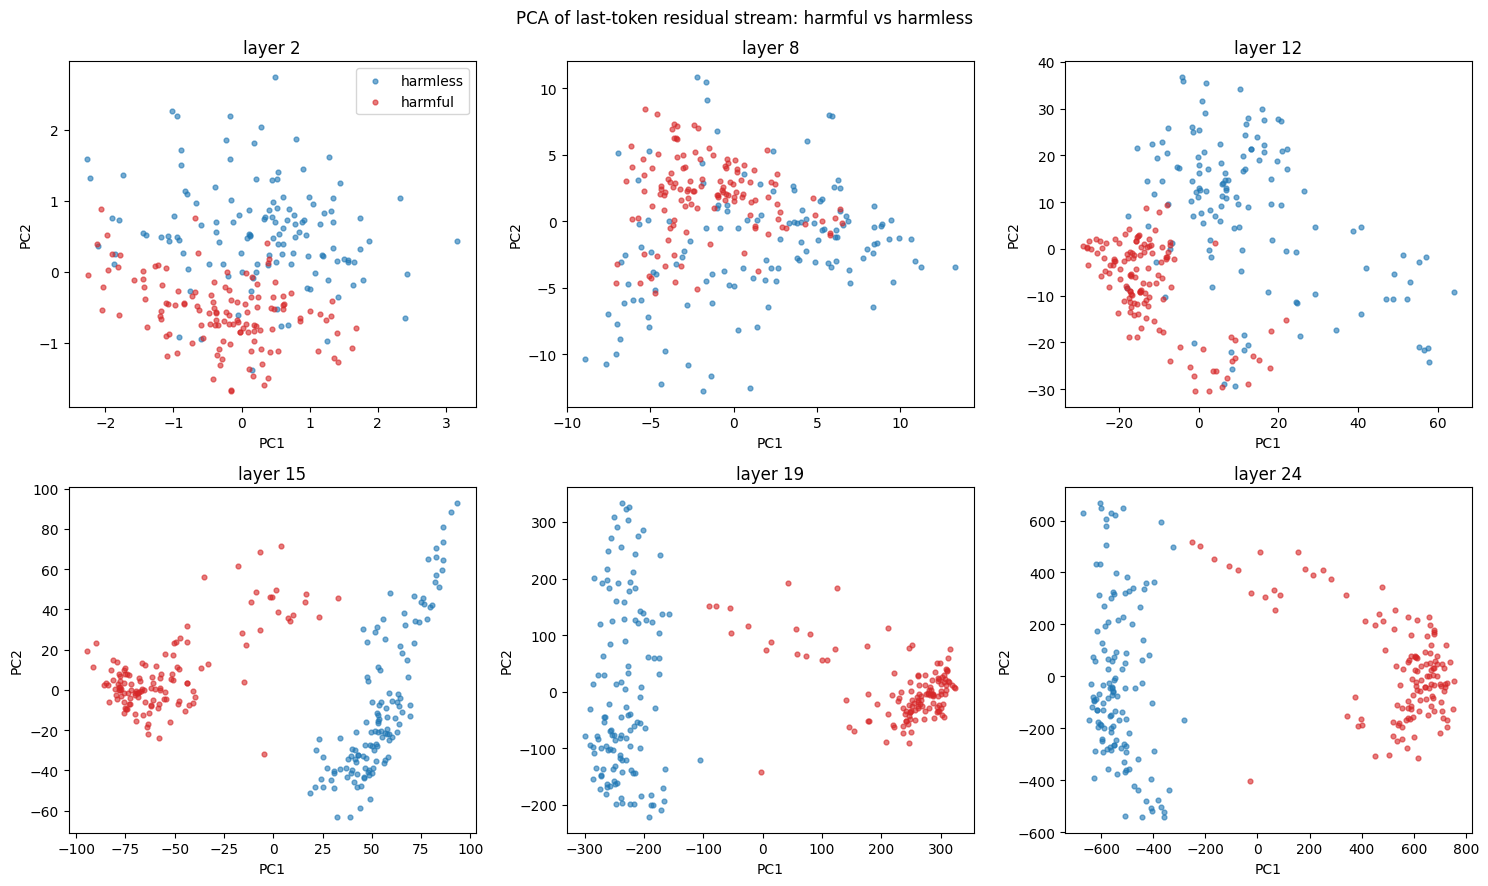

In [9]:
from sklearn.decomposition import PCA

layers_to_plot = [2, 8, 12, 15, 19, 24]
n = harmful_acts.shape[0]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, L in zip(axes.flat, layers_to_plot):
    X = torch.cat([harmful_acts[:, L], harmless_acts[:, L]]).numpy()   # [256, 2048]
    Z = PCA(n_components=2).fit_transform(X)                            # [256, 2]
    ax.scatter(Z[n:, 0], Z[n:, 1], s=12, alpha=0.6, c="tab:blue", label="harmless")
    ax.scatter(Z[:n, 0], Z[:n, 1], s=12, alpha=0.6, c="tab:red",  label="harmful")
    ax.set_title(f"layer {L}")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
axes.flat[0].legend()

plt.suptitle("PCA of last-token residual stream: harmful vs harmless")
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/pca_layers.png", dpi=150)
plt.show()

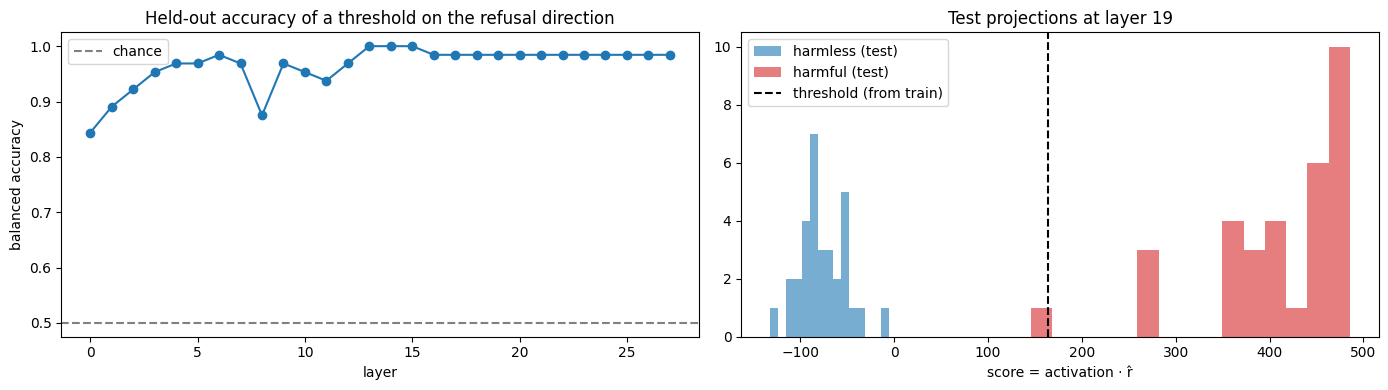

In [10]:
train = torch.load(f"{SAVE_DIR}/activations_train.pt")
test  = torch.load(f"{SAVE_DIR}/activations_test.pt")
dirs  = torch.load(f"{SAVE_DIR}/refusal_dirs.pt")["dirs"]   # [28, 2048]

def project(acts, dirs):
    """acts [N, 28, 2048] · dirs [28, 2048] → scores [N, 28]"""
    return (acts * dirs).sum(dim=-1)

tr_h = project(train["harmful_acts"],      dirs)
tr_b = project(train["harmless_acts"],     dirs)
te_h = project(test["harmful_test_acts"],  dirs)
te_b = project(test["harmless_test_acts"], dirs)

# threshold per layer: midpoint of the two TRAIN means
threshold = (tr_h.mean(0) + tr_b.mean(0)) / 2                       # [28]

# balanced accuracy on TEST prompts
test_acc = ((te_h > threshold).float().mean(0) +
            (te_b <= threshold).float().mean(0)) / 2               # [28]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(test_acc, marker="o")
axes[0].axhline(0.5, ls="--", c="gray", label="chance")
axes[0].set_title("Held-out accuracy of a threshold on the refusal direction")
axes[0].set_xlabel("layer"); axes[0].set_ylabel("balanced accuracy"); axes[0].legend()

L = 19
axes[1].hist(te_b[:, L], bins=15, alpha=0.6, label="harmless (test)", color="tab:blue")
axes[1].hist(te_h[:, L], bins=15, alpha=0.6, label="harmful (test)",  color="tab:red")
axes[1].axvline(threshold[L], c="k", ls="--", label="threshold (from train)")
axes[1].set_title(f"Test projections at layer {L}")
axes[1].set_xlabel("score = activation · r̂"); axes[1].legend()

plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/projection_test.png", dpi=150)
plt.show()